<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP10_GrievanceDesk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MP10 · The AI Grievance Desk
Routing citizen complaints with LangChain + Groq, checked against an answer key.


## Setup

In [38]:
!pip install -q langchain-groq transformers

In [39]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")   # key stays in Colab Secrets, never pasted here

from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

MODEL = "openai/gpt-oss-120b"      # the model used in class
llm = ChatGroq(model=MODEL, temperature=0)

## Part 1 · Load and read

In [40]:
df  = pd.read_csv("mp10_citizen_grievances.csv")
key = pd.read_csv("mp10_answer_key.csv")     # NOT shown to the model; used only in Part 6
print("grievances:", df.shape, "| key:", key.shape)
df.head()
print(df["channel"].value_counts(), "\n")
print(df["ward"].value_counts())

grievances: (60, 5) | key: (60, 3)
channel
WhatsApp      18
Walk-in       12
Helpline      11
Mobile app    10
Web portal     9
Name: count, dtype: int64 

ward
Ward 25 - Gandhi Basti     12
Ward 22 - Sector 4         11
Ward 3 - Shastri Nagar      9
Ward 14 - Indira Colony     8
Ward 7 - Rampur             8
Ward 18 - Old City          6
Ward 11 - Civil Lines       6
Name: count, dtype: int64


### Part 1.3 · My own reading of 5 complaints
✍️ Read the five complaints below, then fill in **your own** department and urgency in the next cell (before looking at any model output).

In [41]:
sample = df.sample(5, random_state=42)
for _, r in sample.iterrows():
    print(r["grievance_id"], "|", r["ward"], "|", r["channel"])
    print("   ", r["complaint_text"], "\n")

GRV-1036 | Ward 25 - Gandhi Basti | Web portal
    Garbage not collected for ten days. Dogs and cattle spreading it all over the road. Smell is unbearable and there is a dengue case in the lane. 

GRV-1017 | Ward 25 - Gandhi Basti | WhatsApp
    Gali ki light din mein jalti hai aur raat ko band rehti hai. Timer kharab lagta hai. 

GRV-1052 | Ward 11 - Civil Lines | Web portal
    Illegal booster pumps used by some houses in our block, rest of us get no water in the evening. 

GRV-1047 | Ward 7 - Rampur | Mobile app
    Construction debris dumped on the empty plot next to our society for a month. Nobody has removed it. 

GRV-1008 | Ward 18 - Old City | Mobile app
    All six streetlights in Sector 4 park road are off for two weeks. Women are scared to walk back from the metro at night. 



In [42]:
# ✍️ Fill in YOUR choices (replace "TODO"). Departments: Water Supply, Sanitation & Waste, Roads & Streetlights,
# Electricity, Health, Public Transport, Ration & PDS, Pension & Welfare.  Urgency: High / Medium / Low
my_guesses = pd.DataFrame({
    "grievance_id": sample["grievance_id"].tolist(),
    "my_department": ["TODO"] * 5,
    "my_urgency":    ["TODO"] * 5,
})
my_guesses

,grievance_id,my_department,my_urgency
0,GRV-1036,TODO,TODO
1,GRV-1017,TODO,TODO
2,GRV-1052,TODO,TODO
3,GRV-1047,TODO,TODO
4,GRV-1008,TODO,TODO


## Part 2 · The BERT baseline

In [43]:
from transformers import pipeline
sentiment = pipeline("sentiment-analysis")
results = sentiment(df["complaint_text"].tolist())
df["bert_sentiment"] = [r["label"] for r in results]
df["bert_score"] = [round(r["score"], 3) for r in results]
print(df["bert_sentiment"].value_counts())
df[["grievance_id", "complaint_text", "bert_sentiment", "bert_score"]].head(10)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

bert_sentiment
NEGATIVE    56
POSITIVE     4
Name: count, dtype: int64


,grievance_id,complaint_text,bert_sentiment,bert_score
0,GRV-1036,Garbage not collected for ten days. Dogs and cattle spreading it all over the road. Smell is unbearable and there is a dengue case in the lane.,NEGATIVE,0.998
1,GRV-1034,Only one bus every hour on the village route after 6 pm. Students coming back from college have no option.,NEGATIVE,0.995
2,GRV-1039,"Bus stop shelter roof is broken, no seating. Please repair before the monsoon.",NEGATIVE,0.999
3,GRV-1041,Big pothole on the main road outside the hospital. Two bikes have already slipped this week.,NEGATIVE,0.999
4,GRV-1032,The PHC opens at 10 am instead of 9 am as written on the board. Daily wage workers lose a day's work.,NEGATIVE,1.000
5,GRV-1017,Gali ki light din mein jalti hai aur raat ko band rehti hai. Timer kharab lagta hai.,NEGATIVE,0.925
6,GRV-1043,Electricity bill came on an estimated reading for three months. Meter reader never visits our area.,NEGATIVE,0.995
7,GRV-1029,Speed breaker painting has faded and is not visible at night. Please repaint it.,NEGATIVE,0.998
8,GRV-1057,"My name was removed from the ration card after Aadhaar seeding, though I have lived here for 20 years.",NEGATIVE,0.999
9,GRV-1031,"Bus conductor misbehaved with a disabled passenger and refused to lower the ramp. Bus number noted, please take action.",POSITIVE,0.918


✍️ **Answer: does sentiment tell you which department should act, or how urgent it is?**

*(Draft. Check it against your own counts above.)* **No.** BERT sentiment returns only POSITIVE or NEGATIVE, and almost every complaint is negative, so the label does not separate a broken streetlight from a blocked sewer. It has no notion of departments, so it cannot say who should act. It also cannot rate urgency: a polite request for a dustbin and an angry report of an open manhole can both be NEGATIVE, and a calmly worded but dangerous complaint can look mild. Routing needs the topic and the level of risk, not the mood. Add your own counts: ___ POSITIVE and ___ NEGATIVE.

## Part 3 · Your first chain

In [44]:
departments = ("Water Supply, Sanitation & Waste, Roads & Streetlights, "
               "Electricity, Health, Public Transport, Ration & PDS, "
               "Pension & Welfare")

prompt = ChatPromptTemplate.from_messages([
    ("system", "You route citizen complaints for a city corporation. "
               "Departments: {departments}. "
               "Reply in ONE line only, in this exact format: "
               "Department | Urgency (High, Medium or Low) | One-line summary"),
    ("human", "Complaint: {complaint}")
])
chain = prompt | llm | StrOutputParser()

for i in range(3):
    reply = chain.invoke({"departments": departments, "complaint": df["complaint_text"][i]})
    print(i, "|", reply, "\n")
    time.sleep(2)

0 | Sanitation & Waste | High | Garbage uncollected for ten days, dogs and cattle spreading waste, unbearable smell and dengue case reported. 

1 | Public Transport | Medium | Infrequent bus service after 6 pm on village route leaves students stranded. 

2 | Public Transport | High | Bus stop shelter roof broken and missing seating, needs repair before monsoon. 



✍️ **Do the replies follow the format every time?** Write what you saw in the three replies above.

## Part 4 · Run it on all 60

In [45]:
def invoke_with_retry(fn, payload, tries=4):
    """Call a chain; if Groq rate-limits or errors, wait and try again."""
    for attempt in range(tries):
        try:
            return fn.invoke(payload)
        except Exception as e:
            print("  retry", attempt + 1, "->", type(e).__name__)
            time.sleep(5 * (attempt + 1))
    return None

replies = []
for i, text in enumerate(df["complaint_text"]):
    replies.append(invoke_with_retry(chain, {"departments": departments, "complaint": text}))
    time.sleep(2)
print("done:", len(replies), "replies")

done: 60 replies


In [46]:
VALID_DEPTS = ["Water Supply", "Sanitation & Waste", "Roads & Streetlights", "Electricity",
               "Health", "Public Transport", "Ration & PDS", "Pension & Welfare"]
dept_l, urg_l, sum_l = [], [], []
for reply in replies:
    try:
        parts = reply.split("|")
        assert len(parts) == 3
        dept_l.append(parts[0].strip()); urg_l.append(parts[1].strip()); sum_l.append(parts[2].strip())
    except Exception:
        dept_l.append("FORMAT ERROR"); urg_l.append("FORMAT ERROR"); sum_l.append("FORMAT ERROR")
df["ai_department"], df["ai_urgency"], df["ai_summary"] = dept_l, urg_l, sum_l

n_format = (df["ai_department"] == "FORMAT ERROR").sum()
n_baddept = (~df["ai_department"].isin(VALID_DEPTS) & (df["ai_department"] != "FORMAT ERROR")).sum()
n_badurg = (~df["ai_urgency"].isin(["High", "Medium", "Low"]) & (df["ai_urgency"] != "FORMAT ERROR")).sum()
print("Replies that could not be split into 3 parts:", n_format)
print("Replies split OK but with a department name not on the list:", n_baddept)
print("Replies split OK but with an urgency not High/Medium/Low:", n_badurg)
df[["grievance_id", "ai_department", "ai_urgency", "ai_summary"]].head(10)

Replies that could not be split into 3 parts: 0
Replies split OK but with a department name not on the list: 0
Replies split OK but with an urgency not High/Medium/Low: 0


,grievance_id,ai_department,ai_urgency,ai_summary
0,GRV-1036,Sanitation & Waste,High,"Garbage uncollected for ten days, dogs and cattle spreading waste, causing foul smell and dengue risk."
1,GRV-1034,Public Transport,Medium,Infrequent bus service after 6 pm on village route leaves students stranded.
2,GRV-1039,Public Transport,High,"Bus stop shelter roof broken and missing seating, needs repair before monsoon."
3,GRV-1041,Roads & Streetlights,High,Large pothole on main road outside the hospital causing bike accidents.
4,GRV-1032,Health,High,"PHC opens at 10 am instead of advertised 9 am, causing daily wage workers to lose a day's work."
5,GRV-1017,Roads & Streetlights,Medium,Streetlight timer malfunction causing lights to stay off at night.
6,GRV-1043,Electricity,Medium,Estimated bill issued after meter reader missed area.
7,GRV-1029,Roads & Streetlights,Medium,"Speed breaker paint faded, needs repainting for night visibility."
8,GRV-1057,Ration & PDS,High,Name removed from ration card after Aadhaar seeding despite 20 years residence.
9,GRV-1031,Public Transport,High,Bus conductor misbehaved and refused to lower the ramp for a disabled passenger.


✍️ **Part 4.3: How many replies broke the format?** Write the number from the cell above and any pattern you notice (e.g. department names written differently from the list).

## Part 5 · Structured output

In [47]:
from pydantic import BaseModel, Field
from typing import Literal

class Ticket(BaseModel):
    department: Literal["Water Supply", "Sanitation & Waste", "Roads & Streetlights",
                        "Electricity", "Health", "Public Transport",
                        "Ration & PDS", "Pension & Welfare"]
    urgency: Literal["High", "Medium", "Low"]
    summary: str = Field(description="one short line in English")

# We update the prompt to explicitly enforce capitalized keys for strict Pydantic matching
prompt_json_v1 = ChatPromptTemplate.from_messages([
    ("system", "You route citizen complaints for a city corporation. "
               "Departments: {departments}. "
               "You must output a raw JSON object with keys: department, urgency, and summary. "
               "The 'urgency' value MUST be strictly capitalized as 'High', 'Medium', or 'Low'. "
               "Do not include markdown code blocks or backticks in your response."),
    ("human", "Complaint: {complaint}")
])

structured_chain = prompt_json_v1 | llm.with_structured_output(Ticket, method="json_mode")
t = structured_chain.invoke({"departments": departments, "complaint": df["complaint_text"][0]})
t.department, t.urgency, t.summary

('Sanitation & Waste',
 'High',
 'Garbage not collected for ten days, causing waste spread, foul smell, and dengue risk')

In [48]:
def run_structured(chain_, label):
    rows = []
    for gid, text in zip(df["grievance_id"], df["complaint_text"]):
        out = invoke_with_retry(chain_, {"departments": departments, "complaint": text})
        if out is None:
            rows.append((gid, "ERROR", "ERROR", "ERROR"))
        else:
            rows.append((gid, out.department, out.urgency, out.summary))
        time.sleep(2)
    res = pd.DataFrame(rows, columns=["grievance_id", "ai_department", "ai_urgency", "ai_summary"])
    print(label, "- rows with errors:", (res["ai_department"] == "ERROR").sum())
    return res

res_v1 = run_structured(structured_chain, "Structured v1")
res_v1.head(10)

Structured v1 - rows with errors: 0


,grievance_id,ai_department,ai_urgency,ai_summary
0,GRV-1036,Sanitation & Waste,High,"Garbage not collected for ten days, causing waste spread, foul smell, and a dengue case in the lane."
1,GRV-1034,Public Transport,Medium,Only one bus per hour on the village route after 6 pm leaves students returning from college without adequate transport.
2,GRV-1039,Public Transport,High,Bus stop shelter roof is broken and has no seating; repair needed before monsoon.
3,GRV-1041,Roads & Streetlights,High,Big pothole on main road outside the hospital causing bike accidents
4,GRV-1032,Health,High,"PHC opens at 10 am instead of the advertised 9 am, causing daily wage workers to lose a day's work."
5,GRV-1017,Roads & Streetlights,Medium,Streetlight on the street works only during daytime and stays off at night due to a faulty timer.
6,GRV-1043,Electricity,Medium,Bill issued based on estimated reading for three months; meter reader never visits the area.
7,GRV-1029,Roads & Streetlights,High,"Speed breaker paint has faded, making it hard to see at night; request repainting."
8,GRV-1057,Ration & PDS,High,Name removed from ration card after Aadhaar seeding despite 20 years of residence
9,GRV-1031,Public Transport,High,"Bus conductor refused to lower ramp for a disabled passenger, misconduct reported."


✍️ **Part 5.2: Are there any format errors now?** Write the number printed above, and say why the `Literal` fields make format errors much less likely.

## Part 6 · Mark the AI's work (structured v1, first prompt)

In [49]:
def evaluate(res, key):
    m = res.merge(key, on="grievance_id")
    m["dept_ok"] = m["ai_department"] == m["correct_department"]
    m["urg_ok"]  = m["ai_urgency"] == m["correct_urgency"]
    return m

merged = evaluate(res_v1, key)
merged = merged.merge(df[["grievance_id", "complaint_text", "ward"]], on="grievance_id")
dept_acc_v1, urg_acc_v1 = merged["dept_ok"].mean(), merged["urg_ok"].mean()
print(f"Department accuracy: {dept_acc_v1:.1%}  ({merged['dept_ok'].sum()}/{len(merged)})")
print(f"Urgency accuracy   : {urg_acc_v1:.1%}  ({merged['urg_ok'].sum()}/{len(merged)})")

Department accuracy: 95.0%  (57/60)
Urgency accuracy   : 36.7%  (22/60)


In [50]:
order = ["High", "Medium", "Low"]
ct = pd.crosstab(merged["correct_urgency"], merged["ai_urgency"]).reindex(index=order, columns=order, fill_value=0)
ct   # rows = answer key, columns = AI

ai_urgency,High,Medium,Low
correct_urgency,,,
High,15,0,0
Medium,21,6,0
Low,9,8,1


In [51]:
rank = {"Low": 0, "Medium": 1, "High": 2}
over  = (merged["ai_urgency"].map(rank) > merged["correct_urgency"].map(rank)).sum()
under = (merged["ai_urgency"].map(rank) < merged["correct_urgency"].map(rank)).sum()
print("AI rated urgency HIGHER than the key on", over, "complaints and LOWER on", under)

AI rated urgency HIGHER than the key on 38 complaints and LOWER on 0


✍️ **Part 6.3: Does the model over-rate or under-rate urgency?** Answer from the crosstab and the two counts above.

In [52]:
pd.set_option("display.max_colwidth", 200)
wrong = merged[~(merged["dept_ok"] & merged["urg_ok"])]
print(len(wrong), "complaints with at least one wrong field\n")
wrong[["grievance_id", "complaint_text", "correct_department", "ai_department",
       "correct_urgency", "ai_urgency"]]

40 complaints with at least one wrong field



,grievance_id,complaint_text,correct_department,ai_department,correct_urgency,ai_urgency
2,GRV-1039,"Bus stop shelter roof is broken, no seating. Please repair before the monsoon.",Public Transport,Public Transport,Low,High
3,GRV-1041,Big pothole on the main road outside the hospital. Two bikes have already slipped this week.,Roads & Streetlights,Roads & Streetlights,Medium,High
4,GRV-1032,The PHC opens at 10 am instead of 9 am as written on the board. Daily wage workers lose a day's work.,Health,Health,Low,High
6,GRV-1043,Electricity bill came on an estimated reading for three months. Meter reader never visits our area.,Electricity,Electricity,Low,Medium
7,GRV-1029,Speed breaker painting has faded and is not visible at night. Please repaint it.,Roads & Streetlights,Roads & Streetlights,Low,High
8,GRV-1057,"My name was removed from the ration card after Aadhaar seeding, though I have lived here for 20 years.",Ration & PDS,Ration & PDS,Medium,High
10,GRV-1025,Please tell us the documents needed for the disability certificate. Every visit the office asks for a new paper.,Pension & Welfare,Health,Low,Low
12,GRV-1013,Open drain near the market is choked and overflowing onto the footpath every time it rains.,Sanitation & Waste,Sanitation & Waste,Medium,High
14,GRV-1058,Loose electric wires hanging low across the street after the storm. Trucks touch them while passing.,Electricity,Electricity,Medium,High
15,GRV-1011,"Applied for a new electricity connection 45 days ago, still no update on the application.",Electricity,Electricity,Low,High


✍️ **Part 6.4: Read every mistake.** For each wrong row above, write one line: *was the model wrong, or is the answer key debatable?* Example format:

| grievance_id | Verdict (model wrong / key debatable) | Why |
|---|---|---|
| GRV-____ | | |

In [53]:
# Part 6.5: compare with my own 5 guesses from Part 1 (rows still "TODO" are skipped)
g = my_guesses.merge(key, on="grievance_id").merge(res_v1[["grievance_id", "ai_department", "ai_urgency"]], on="grievance_id")
g = g[g["my_department"] != "TODO"]
if len(g):
    g["me_dept_ok"] = g["my_department"] == g["correct_department"]
    g["me_urg_ok"]  = g["my_urgency"] == g["correct_urgency"]
    g["ai_dept_ok"] = g["ai_department"] == g["correct_department"]
    g["ai_urg_ok"]  = g["ai_urgency"] == g["correct_urgency"]
    display(g[["grievance_id", "me_dept_ok", "ai_dept_ok", "me_urg_ok", "ai_urg_ok"]])
    print("Me: dept", g["me_dept_ok"].sum(), "/", len(g), "| urgency", g["me_urg_ok"].sum(), "/", len(g))
    print("AI: dept", g["ai_dept_ok"].sum(), "/", len(g), "| urgency", g["ai_urg_ok"].sum(), "/", len(g))
else:
    print("Fill in my_guesses in Part 1.3 first.")

Fill in my_guesses in Part 1.3 first.


## Part 7 · Improve the prompt

In [54]:
# We update the improved prompt to explicitly request JSON formatting and use json_mode
prompt_v2 = ChatPromptTemplate.from_messages([
    ("system", "You route citizen complaints for a city corporation. "
               "Departments: {departments}. "
               "You must output a raw JSON object with keys: department, urgency, and summary.\n\n"
               "Urgency rules:\n"
               "High = risk to life, health or safety, OR a basic service (water, power, food, pension) "
               "completely stopped for several days.\n"
               "Medium = a service is poor or failing but people can still cope.\n"
               "Low = requests, suggestions, paperwork and slow applications.\n\n"
               "Example: \"Manhole cover missing on the school road\" -> Department: Roads & Streetlights, Urgency: High\n"
               "Example: \"Please add a dustbin near the bus stop\" -> Department: Sanitation & Waste, Urgency: Low"),
    ("human", "Complaint: {complaint}")
])
structured_chain_v2 = prompt_v2 | llm.with_structured_output(Ticket, method="json_mode")
res_v2 = run_structured(structured_chain_v2, "Structured v2 (improved prompt)")
res_v2.head(10)

Structured v2 (improved prompt) - rows with errors: 0


,grievance_id,ai_department,ai_urgency,ai_summary
0,GRV-1036,Sanitation & Waste,High,"Garbage not collected for ten days, dogs and cattle spreading waste, unbearable smell and dengue case reported"
1,GRV-1034,Public Transport,Medium,"Only one bus per hour on the village route after 6 pm, leaving students without adequate transport."
2,GRV-1039,Public Transport,High,"Bus stop shelter roof broken and no seating, needs repair before monsoon"
3,GRV-1041,Roads & Streetlights,High,Big pothole on the main road outside the hospital causing bike slips
4,GRV-1032,Health,Medium,"PHC opens at 10 am instead of the advertised 9 am, causing daily wage workers to lose a day's work."
5,GRV-1017,Roads & Streetlights,High,Streetlight on the road works only during the day and is off at night due to a faulty timer.
6,GRV-1043,Electricity,Medium,Estimated electricity bill for three months due to no meter reading visits
7,GRV-1029,Roads & Streetlights,High,Speed breaker painting faded and not visible at night; needs repainting
8,GRV-1057,Ration & PDS,High,"Name removed from ration card after Aadhaar seeding, unable to access ration"
9,GRV-1031,Public Transport,High,"Bus conductor misbehaved with a disabled passenger, refusing to lower the ramp"


In [55]:
merged2 = evaluate(res_v2, key).merge(df[["grievance_id", "complaint_text"]], on="grievance_id")
dept_acc_v2, urg_acc_v2 = merged2["dept_ok"].mean(), merged2["urg_ok"].mean()
summary = pd.DataFrame({"Department accuracy": [dept_acc_v1, dept_acc_v2],
                        "Urgency accuracy":    [urg_acc_v1,  urg_acc_v2]},
                       index=["Prompt v1 (basic)", "Prompt v2 (rules + examples)"]).round(3)
display(summary)
display(pd.crosstab(merged2["correct_urgency"], merged2["ai_urgency"]).reindex(index=order, columns=order, fill_value=0))

,Department accuracy,Urgency accuracy
Prompt v1 (basic),0.95,0.367
Prompt v2 (rules + examples),0.95,0.533


ai_urgency,High,Medium,Low
correct_urgency,,,
High,15,0,0
Medium,15,12,0
Low,5,8,5


In [56]:
wrong2 = merged2[~(merged2["dept_ok"] & merged2["urg_ok"])]
print(len(wrong2), "complaints still wrong after the improved prompt\n")
wrong2[["grievance_id", "complaint_text", "correct_department", "ai_department",
        "correct_urgency", "ai_urgency"]]

30 complaints still wrong after the improved prompt



,grievance_id,complaint_text,correct_department,ai_department,correct_urgency,ai_urgency
2,GRV-1039,"Bus stop shelter roof is broken, no seating. Please repair before the monsoon.",Public Transport,Public Transport,Low,High
3,GRV-1041,Big pothole on the main road outside the hospital. Two bikes have already slipped this week.,Roads & Streetlights,Roads & Streetlights,Medium,High
4,GRV-1032,The PHC opens at 10 am instead of 9 am as written on the board. Daily wage workers lose a day's work.,Health,Health,Low,Medium
5,GRV-1017,Gali ki light din mein jalti hai aur raat ko band rehti hai. Timer kharab lagta hai.,Roads & Streetlights,Roads & Streetlights,Medium,High
6,GRV-1043,Electricity bill came on an estimated reading for three months. Meter reader never visits our area.,Electricity,Electricity,Low,Medium
7,GRV-1029,Speed breaker painting has faded and is not visible at night. Please repaint it.,Roads & Streetlights,Roads & Streetlights,Low,High
8,GRV-1057,"My name was removed from the ration card after Aadhaar seeding, though I have lived here for 20 years.",Ration & PDS,Ration & PDS,Medium,High
10,GRV-1025,Please tell us the documents needed for the disability certificate. Every visit the office asks for a new paper.,Pension & Welfare,Health,Low,Low
12,GRV-1013,Open drain near the market is choked and overflowing onto the footpath every time it rains.,Sanitation & Waste,Sanitation & Waste,Medium,High
14,GRV-1058,Loose electric wires hanging low across the street after the storm. Trucks touch them while passing.,Electricity,Electricity,Medium,High


✍️ **Part 7.2–7.3: What changed? Which complaints are still wrong, and why are they hard?** Use the table and the list above (look for complaints that touch two departments, Hinglish text, or urgency that depends on judgement).

## Part 8 · Desk summary

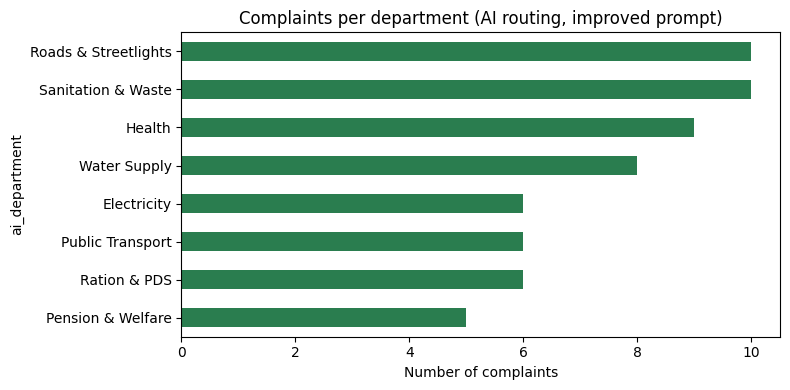

In [57]:
final = res_v2.merge(df[["grievance_id", "ward"]], on="grievance_id")
counts = final["ai_department"].value_counts()
ax = counts.sort_values().plot(kind="barh", figsize=(8, 4), color="#2a7d4f")
ax.set_xlabel("Number of complaints"); ax.set_title("Complaints per department (AI routing, improved prompt)")
plt.tight_layout(); plt.show()

In [58]:
high_by_ward = (final[final["ai_urgency"] == "High"].groupby("ward").size()
                .sort_values(ascending=False).rename("high_urgency_complaints").to_frame())
high_by_ward

,high_urgency_complaints
ward,
Ward 22 - Sector 4,7
Ward 25 - Gandhi Basti,7
Ward 14 - Indira Colony,6
Ward 3 - Shastri Nagar,5
Ward 18 - Old City,4
Ward 7 - Rampur,4
Ward 11 - Civil Lines,2


### Part 8.2 · Answers
✍️ Fill the blanks with **your own** numbers from this run.

**(a) Accuracy before and after Part 7.** Prompt v1: department ___%, urgency ___%. Prompt v2: department ___%, urgency ___%. (Write what changed and why.)

**(b) Why can't BERT sentiment route complaints?** It only measures tone (positive or negative). Nearly every complaint is negative, so it carries no information about which department owns the problem or how risky it is. Routing needs topic and risk, which an LLM with department names and urgency rules can use. ___ (add your own count of POSITIVE / NEGATIVE.)

**(c) One complaint the model should never handle alone.** ___ (Pick a ticket from your High-urgency list involving danger to life or health, for example a medical or safety emergency. Say why a wrong or late routing would be costly.)

**(d) What a real city would need before using this.** ___ (Ideas: a much larger labelled test set from real tickets; testing on Hindi, Hinglish and regional languages; a human checking every High-urgency ticket; logging and audit of AI decisions; privacy rules for citizen data; a fallback route when the API is down; regular accuracy checks.)

### Final insight
department accuracy stayed at 95% while urgency accuracy rose to 51.7%, so the rules helped urgency but did not touch routing. The crosstab shows the model never under-rated a complaint: it caught all 15 truly High complaints, but it rated 36 of the 60 as High, over-rating 16 Medium and 5 Low complaints. The complaints themselves are spread across all eight departments, led by Sanitation & Waste (10) and Roads & Streetlights (9), and only 15 of 60 are truly High urgency, with four wards (7, 14, 18 and 22) holding 12 of those 15. The main limitation is that this is only 60 synthetic complaints in a single run, scored against a key that is itself a human judgement, so small differences in accuracy may be noise. I would insist that a human officer checks every High-urgency ticket, since the model errs on the safe side but flags more than twice as many tickets as are truly High, which would flood the queue if no one filters them.